# Day 6

### Data Science

Core tools -> Excel, RDBMS, Hadoop, Spark

In [1]:
import numpy as np, pandas as pd

In [3]:
df1 = pd.read_csv('churn.csv')

In [4]:
df1

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [19]:
import seaborn as sns

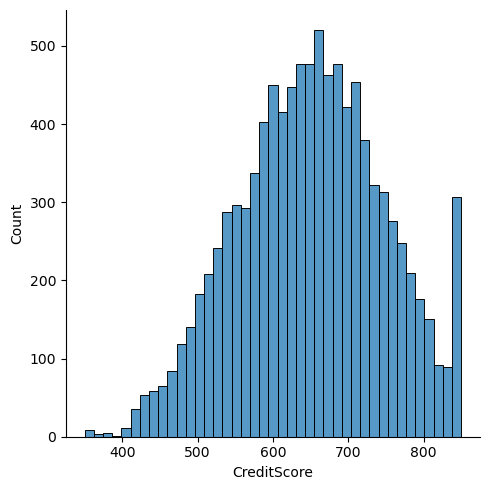

In [18]:
sns.displot(df1.CreditScore)

<AxesSubplot: xlabel='CreditScore'>

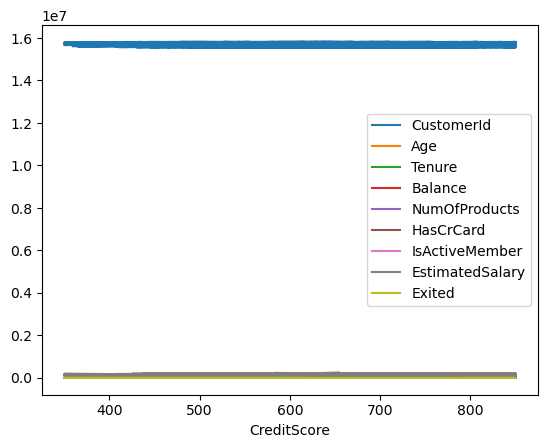

In [16]:
df1.plot('CreditScore')

<AxesSubplot: >

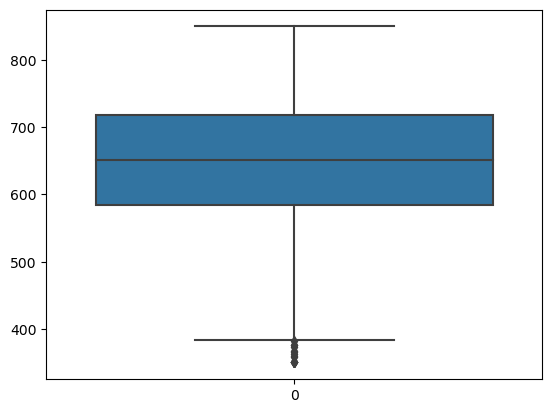

In [20]:
sns.boxplot(df1.CreditScore)

In [23]:
q3 = df1.CreditScore.quantile(0.75)
q3

718.0

In [25]:
q1 = df1.CreditScore.quantile(0.25)
q1

584.0

In [27]:
iqr = q3-q1
iqr

134.0

In [29]:
uw_outlier = q3 + 1.5*iqr
uw_outlier

919.0

In [31]:
lw_outlier = q1 - 1.5*iqr
lw_outlier

383.0

In [32]:
df1['Geography'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [33]:
df1['Geography'].value_counts()

France     5014
Germany    2509
Spain      2477
Name: Geography, dtype: int64

In [35]:
df1['Geography'].mode() # highest count

0    France
Name: Geography, dtype: object

<AxesSubplot: xlabel='Geography', ylabel='count'>

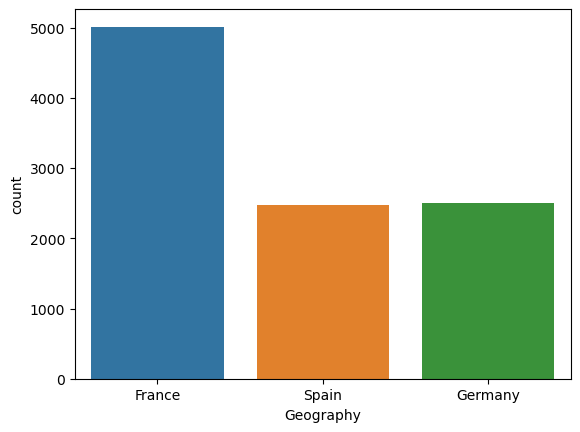

In [39]:
sns.countplot(x=df1.Geography)

<AxesSubplot: xlabel='CreditScore', ylabel='Count'>

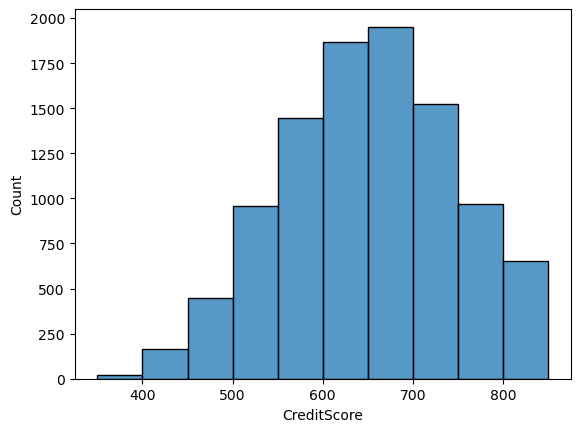

In [41]:
sns.histplot(df1.CreditScore, bins=10)

In [55]:
df1.iloc[df1[df1['CreditScore']>600].index]

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9994,15719294,Wood,800,France,Female,29,2,0.00,2,0,0,167773.55,0
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [61]:
df1.loc[df1['CreditScore']>600,'Tenure':]

,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2,0.00,1,1,1,101348.88,1
1,1,83807.86,1,0,1,112542.58,0
3,1,0.00,2,0,0,93826.63,0
4,2,125510.82,1,1,1,79084.10,0
5,8,113755.78,2,1,0,149756.71,1
...,...,...,...,...,...,...,...
9994,2,0.00,2,0,0,167773.55,0
9995,5,0.00,2,1,0,96270.64,0
9997,7,0.00,1,0,1,42085.58,1
9998,3,75075.31,2,1,0,92888.52,1


In [62]:
df1.groupby('Geography').agg({'CreditScore':np.mean,'Balance':['min','max','mean'],'EstimatedSalary':['min','max','mean',np.std],'Exited':'mean'})

CreditScore   Balance                           EstimatedSalary  \
                 mean       min        max           mean             min   
Geography                                                                   
France     649.668329      0.00  238387.56   62092.636516           90.07   
Germany    651.453567  27288.43  214346.96  119730.116134           11.58   
Spain      651.333872      0.00  250898.09   61818.147763          417.41   

                                                     Exited  
                 max           mean           std      mean  
Geography                                                    
France     199929.17   99899.180814  57336.289016  0.161548  
Germany    199970.74  101113.435102  58263.011501  0.324432  
Spain      199992.48   99440.572281  57103.678091  0.166734

In [63]:
df1.groupby('Geography').Age.mean()

Geography
France     38.511767
Germany    39.771622
Spain      38.890997
Name: Age, dtype: float64

In [65]:
df1.groupby('Geography').agg({'Age':'mean'})

,Age
Geography,
France,38.511767
Germany,39.771622
Spain,38.890997


In [66]:
df1.groupby(['Geography','Gender']).Exited.sum()

Geography  Gender
France     Female    460
           Male      350
Germany    Female    448
           Male      366
Spain      Female    231
           Male      182
Name: Exited, dtype: int64

In [68]:
pd.crosstab(df1.Geography,[df1.Exited,df1.Gender])

Exited         0            1     
Gender    Female  Male Female Male
Geography                         
France      1801  2403    460  350
Germany      745   950    448  366
Spain        858  1206    231  182

## SQL

In [1]:
import sqlite3

In [4]:
conn = sqlite3.connect('test.db')

In [ ]:
conn.execute('''CREATE TABLE EMPLOYEE''')